# 03 — Train & Evaluate on Local GPU

Melatih baseline (TF-IDF+LR, TextCNN, BiLSTM, IndoBERTweet hard MTL, IndoBERTweet soft MTL) di GPU lokal.
Hasil: checkpoint, prediksi CSV, metrik CSV, confusion/PR/reliability PNG di `artifacts/`.

In [1]:
from pathlib import Path
import sys
import json
import time

import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, average_precision_score
from torch.utils.data import DataLoader

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from discourse.utils import load_yaml, set_seed, get_device, ensure_dir
from discourse.train import run_training
from discourse.predict import load_checkpoint, predict_dataframe
from discourse.evaluate import export_metrics_and_figures, select_thresholds
from discourse.calibration import calibrate_report
from discourse.datasets import DiscourseDataset, collate_batch

device = get_device("cuda")
print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.12.0.dev20260407+cu128
cuda available: True
device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [2]:
all_df = pd.read_parquet(ROOT / "data/processed/all_splits.parquet")
train_df = all_df[all_df.split == "train"].copy()
val_df = all_df[all_df.split == "validation"].copy()
test_df = all_df[all_df.split == "test"].copy()
print({k: len(v) for k, v in {"train": train_df, "val": val_df, "test": test_df}.items()})

{'train': 19897, 'val': 4287, 'test': 4264}


## E0 — TF-IDF + Logistic Regression (CPU sanity baseline)

In [3]:
def run_tfidf_lr(train_df, val_df, test_df, task_col_hard, task_name):
    tr = train_df[train_df[task_col_hard].notna()].copy()
    va = val_df[val_df[task_col_hard].notna()].copy()
    te = test_df[test_df[task_col_hard].notna()].copy()
    vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
    Xtr = vec.fit_transform(tr["text_proc"].astype(str))
    Xva = vec.transform(va["text_proc"].astype(str))
    Xte = vec.transform(te["text_proc"].astype(str))
    clf = LogisticRegression(max_iter=200, class_weight="balanced", n_jobs=-1)
    clf.fit(Xtr, tr[task_col_hard].astype(int))
    # threshold on val macro-F1
    pva = clf.predict_proba(Xva)[:, 1]
    best_t, best_f1 = 0.5, -1
    yva = va[task_col_hard].astype(int).to_numpy()
    for t in np.linspace(0.1, 0.9, 17):
        f1 = f1_score(yva, (pva >= t).astype(int), average="macro", zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, float(t)
    pte = clf.predict_proba(Xte)[:, 1]
    yte = te[task_col_hard].astype(int).to_numpy()
    pred = (pte >= best_t).astype(int)
    return {
        "experiment_id": "E0_tfidf_lr",
        "task": task_name,
        "split": "test",
        "n": int(len(te)),
        "threshold": best_t,
        "macro_f1": float(f1_score(yte, pred, average="macro", zero_division=0)),
        "pos_f1": float(f1_score(yte, pred, pos_label=1, zero_division=0)),
        "average_precision": float(average_precision_score(yte, pte)) if len(np.unique(yte)) > 1 else None,
    }

e0_rows = [
    run_tfidf_lr(train_df, val_df, test_df, "hard_tox", "tox"),
    run_tfidf_lr(train_df, val_df, test_df, "hard_pol", "pol"),
]
e0_df = pd.DataFrame(e0_rows)
ensure_dir(ROOT / "artifacts/metrics")
e0_df.to_csv(ROOT / "artifacts/metrics/E0_tfidf_lr_test_metrics.csv", index=False)
display(e0_df)

C:\Users\achma\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


C:\Users\achma\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,experiment_id,task,split,n,threshold,macro_f1,pos_f1,average_precision
0,E0_tfidf_lr,tox,test,4003,0.55,0.675649,0.417983,0.354321
1,E0_tfidf_lr,pol,test,3870,0.55,0.674341,0.476253,0.411171


## Deep models on GPU (E1a TextCNN, E1b BiLSTM, E1c/E2 IndoBERTweet hard MTL, E3 soft MTL)

In [4]:
exp_configs = [
    "configs/textcnn.yaml",
    "configs/bilstm.yaml",
    "configs/indobertweet.yaml",
    "configs/multitask_soft.yaml",
]

all_metrics = [e0_df]
run_summaries = []

for cfg_path in exp_configs:
    cfg = load_yaml(ROOT / cfg_path)
    exp_id = cfg["experiment_id"]
    out_dir = ROOT / "artifacts/checkpoints" / exp_id
    print("\n=== Training", exp_id, "===")
    t0 = time.time()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    result = run_training(cfg, train_df, val_df, out_dir=out_dir, device_prefer="cuda")
    elapsed = time.time() - t0
    peak_vram = None
    if torch.cuda.is_available():
        peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2)
    print(f"done {exp_id} in {elapsed/60:.1f} min | best={result['best_score']:.4f} | peak_vram_mb={peak_vram}")

    model, cfg_loaded, thresholds, vocab, tokenizer, device = load_checkpoint(result["best_path"], "cuda")
    # refresh thresholds on validation
    val_pred = predict_dataframe(model, val_df, cfg_loaded, vocab, tokenizer, device)
    thresholds = select_thresholds(val_pred)
    test_pred = predict_dataframe(model, test_df, cfg_loaded, vocab, tokenizer, device)
    test_pred["experiment_id"] = exp_id
    test_pred["split"] = "test"

    metrics_df = export_metrics_and_figures(
        exp_id,
        test_pred,
        thresholds,
        split_name="test",
        metrics_dir=ROOT / "artifacts/metrics",
        figures_dir=ROOT / "artifacts/figures",
    )
    cal_df = calibrate_report(
        test_pred,
        exp_id,
        figures_dir=ROOT / "artifacts/figures",
        tables_dir=ROOT / "artifacts/tables",
    )
    all_metrics.append(metrics_df)
    run_summaries.append({
        "experiment_id": exp_id,
        "device": result["device"],
        "best_val_mean_macro_f1": result["best_score"],
        "train_minutes": elapsed / 60,
        "peak_vram_mb": peak_vram,
        "thresholds": json.dumps(thresholds),
    })
    display(metrics_df)
    display(cal_df)

summary_df = pd.DataFrame(run_summaries)
summary_df.to_csv(ROOT / "artifacts/metrics/training_summary.csv", index=False)
combined = pd.concat(all_metrics, ignore_index=True)
combined.to_csv(ROOT / "artifacts/metrics/all_experiments_test_metrics.csv", index=False)
display(summary_df)
display(combined)


=== Training E1a_textcnn ===


  0%|          | 0/67 [00:00<?, ?it/s]

[E1a_textcnn] epoch=1 loss=0.3236 mean_macro_f1=0.6270 device=cuda


  0%|          | 0/67 [00:00<?, ?it/s]

[E1a_textcnn] epoch=2 loss=0.2345 mean_macro_f1=0.6326 device=cuda


  0%|          | 0/67 [00:00<?, ?it/s]

... (63 outputs left out)

,experiment_id,split,task,n,macro_f1,pos_f1,precision,recall,average_precision,roc_auc,threshold,n_multi,mse,cross_entropy
0,E3_soft_mtl,test,tox,4003,0.700751,0.456522,0.398104,0.535032,0.453302,0.895829,0.30,1836,0.062853,0.430745
1,E3_soft_mtl,test,pol,3870,0.685720,0.466780,0.460504,0.473230,0.483541,0.864322,0.45,1836,0.058139,0.439512


,experiment_id,task,n,ece,brier
0,E3_soft_mtl,tox,4003,0.018230,0.054852
1,E3_soft_mtl,pol,3870,0.045041,0.099092


,experiment_id,device,best_val_mean_macro_f1,train_minutes,peak_vram_mb,thresholds
0,E1a_textcnn,cuda,0.640431,1.216275,193.733887,"{""tox"": 0.1, ""pol"": 0.15000000000000002}"
1,E1b_bilstm,cuda,0.660125,2.699520,232.740723,"{""tox"": 0.2, ""pol"": 0.2}"
2,E1c_indobertweet,cuda,0.721365,21.533060,2441.666992,"{""tox"": 0.35, ""pol"": 0.30000000000000004}"
3,E3_soft_mtl,cuda,0.717687,19.161943,2842.669922,"{""tox"": 0.30000000000000004, ""pol"": 0.45000000..."


,experiment_id,task,split,n,threshold,macro_f1,pos_f1,average_precision,precision,recall,roc_auc,n_multi,mse,cross_entropy
0,E0_tfidf_lr,tox,test,4003,0.55,0.675649,0.417983,0.354321,NaN,NaN,NaN,NaN,NaN,NaN
1,E0_tfidf_lr,pol,test,3870,0.55,0.674341,0.476253,0.411171,NaN,NaN,NaN,NaN,NaN,NaN
2,E1a_textcnn,tox,test,4003,0.10,0.637131,0.337625,0.294375,0.306494,0.375796,0.802636,1836.0,0.096518,0.727996
3,E1a_textcnn,pol,test,3870,0.15,0.643880,0.402878,0.368667,0.375000,0.435233,0.793686,1836.0,0.096531,0.714198
4,E1b_bilstm,tox,test,4003,0.20,0.662719,0.389474,0.314636,0.331839,0.471338,0.820580,1836.0,0.080628,0.546397
5,E1b_bilstm,pol,test,3870,0.20,0.650333,0.431046,0.379205,0.359954,0.537133,0.804646,1836.0,0.085786,0.611002
6,E1c_indobertweet,tox,test,4003,0.35,0.704351,0.458333,0.432310,0.430168,0.490446,0.884476,1836.0,0.078220,0.638826
7,E1c_indobertweet,pol,test,3870,0.30,0.702602,0.511561,0.468934,0.439752,0.611399,0.857334,1836.0,0.078504,0.596225
8,E3_soft_mtl,tox,test,4003,0.30,0.700751,0.456522,0.453302,0.398104,0.535032,0.895829,1836.0,0.062853,0.430745
9,E3_soft_mtl,pol,test,3870,0.45,0.685720,0.466780,0.483541,0.460504,0.473230,0.864322,1836.0,0.058139,0.439512


Key local artifacts:

artifacts/metrics/*.csv: 7 files
 - artifacts\metrics\all_experiments_test_metrics.csv
 - artifacts\metrics\E0_tfidf_lr_test_metrics.csv
 - artifacts\metrics\E1a_textcnn_test_metrics.csv
 - artifacts\metrics\E1b_bilstm_test_metrics.csv
 - artifacts\metrics\E1c_indobertweet_test_metrics.csv
 - artifacts\metrics\E3_soft_mtl_test_metrics.csv
 - artifacts\metrics\training_summary.csv

artifacts/predictions/*.csv: 4 files
 - artifacts\predictions\E1a_textcnn_test_preds.csv
 - artifacts\predictions\E1b_bilstm_test_preds.csv
 - artifacts\predictions\E1c_indobertweet_test_preds.csv
 - artifacts\predictions\E3_soft_mtl_test_preds.csv

artifacts/figures/*_cm.png: 8 files
 - artifacts\figures\E1a_textcnn_test_pol_cm.png
 - artifacts\figures\E1a_textcnn_test_tox_cm.png
 - artifacts\figures\E1b_bilstm_test_pol_cm.png
 - artifacts\figures\E1b_bilstm_test_tox_cm.png
 - artifacts\figures\E1c_indobertweet_test_pol_cm.png
 - artifacts\figures\E1c_indobertweet_test_tox_cm.png
 - art

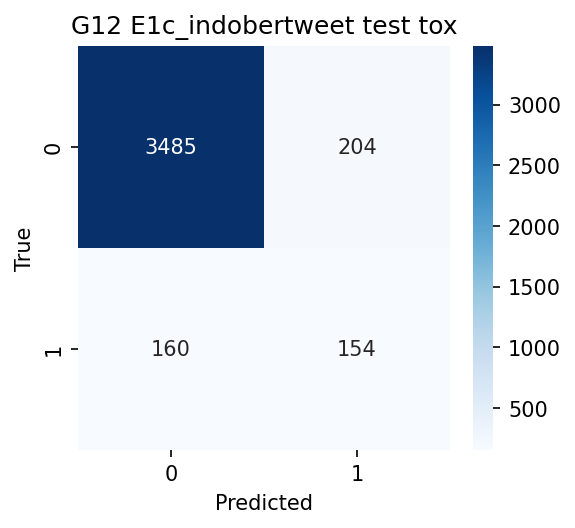

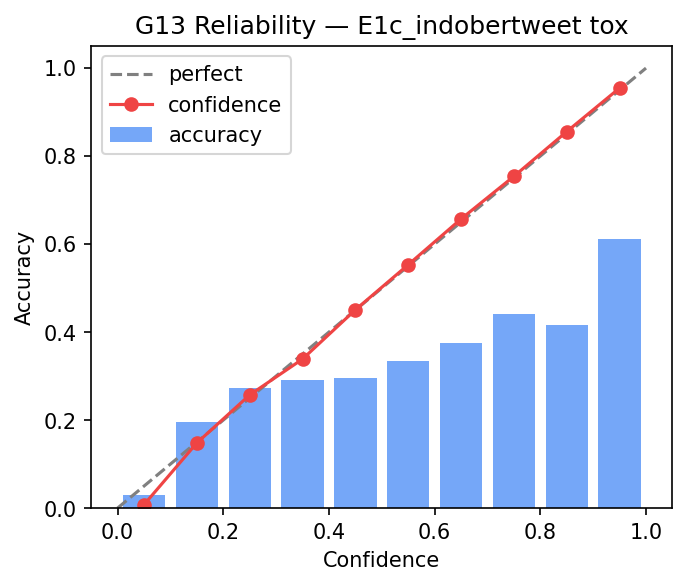

In [5]:
from IPython.display import Image, display

print("Key local artifacts:")
for pattern in [
    "artifacts/metrics/*.csv",
    "artifacts/predictions/*.csv",
    "artifacts/figures/*_cm.png",
    "artifacts/figures/*_pr.png",
    "artifacts/figures/*_reliability.png",
]:
    files = sorted(ROOT.glob(pattern))
    print(f"\n{pattern}: {len(files)} files")
    for f in files[:12]:
        print(" -", f.relative_to(ROOT))

# show a few figures
for f in sorted((ROOT / "artifacts/figures").glob("E1c*_test_tox_cm.png"))[:1]:
    display(Image(filename=str(f)))
for f in sorted((ROOT / "artifacts/figures").glob("E1c*_tox_reliability.png"))[:1]:
    display(Image(filename=str(f)))